# 40 Customer features and peer groups

This notebook builds the per-customer inputs that every later notebook uses:

1. **Full-year features** (`customer_features`), designed around what each technology physically does to a home's
   hourly use: solar panels lower midday grid use, EV chargers draw several kW for hours at a time, heat pumps add
   load in cold weather.
2. **Labels**: which customers are on the EV, heat pump (HP) and solar (PV) lists, and how those groups differ on
   the features.
3. **Peer groups and the peer index**: customers grouped by the shape, size and temperature response of their use,
   and each group's average use at every hour of the year. Comparing a customer with their peers on the same day
   removes the weather, season and calendar effects that everyone shares.
4. **Cached arrays and `customer_status`**: hourly use as customers × days × 24 arrays for the models, and one row
   per customer number saying whether and why they are in the analysis.

The other feature families (signatures, peak load, appliance rules, heat-pump physics, EV night features,
peer-relative and mid-year change features) are computed from these inputs by the `avangrid` package when the
models run; they are listed at the end of this notebook.

Run from the project folder after notebooks 10–30. It takes about a minute.

## Setup

`OMP_NUM_THREADS` is set to 1 before scikit-learn is imported, as in every notebook that fits models: it keeps
results identical between runs and stops scikit-learn's thread pools from slowing down the many small models in
notebook 50.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import math

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda'

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')

## Per-customer features

Each feature summarises one customer's full year of hourly use in `ami_analysis`, together with the weather and time-of-day variables in `weather_features` from notebook 30. The features are designed around what each technology physically does to a household's load:

**Solar PV.** `hourly_kwh` is never negative, so it appears to measure only electricity drawn **from** the grid. When panels are generating, the home draws less or nothing, so midday use drops, especially in summer.

| Feature | Meaning |
|---|---|
| `summer_midday_zero_share` | Share of Apr–Sep hours from 11 am–3 pm (`hour_ending` 11–15) with use under 0.05 kWh |
| `summer_midday_kwh`, `summer_night_kwh` | Average use at summer midday and at summer night (`hour_ending` 1–6) |
| `summer_midday_night_ratio` | Midday ÷ night use in summer. Low for solar homes; about 1 or higher for others |
| `midday_summer_winter_ratio` | Summer midday ÷ winter midday (Nov–Jan) use. Low for solar, which generates far more in summer |

The night-time features matter because an **empty or seasonal home** also has near-zero midday use, but it is near zero at night too. A solar home is not.

**EV.** A home charger draws a lot of power (often about 7 kW) for a few hours at a time, regardless of the weather.

| Feature | Meaning |
|---|---|
| `share_high_hours` | Share of hours at least 3 kWh above the customer's own usual (median) use for that hour of day |
| `high_sessions` | Number of separate runs of such high hours, a rough count of charging sessions |
| `sharp_rises` | Number of times use jumps by 3 kWh or more from one hour to the next, like a charger switching on |

**Heat pump.** A heat pump uses more electricity the colder it gets.

| Feature | Meaning |
|---|---|
| `heating_slope` | Extra kWh per day for each degree the day's average temperature is below 55°F (fitted on days below 55°F) |
| `cooling_slope` | Extra kWh per day for each degree above 65°F (fitted on days above 65°F). Heat pumps also cool |
| `heating_slope_rel`, `cooling_slope_rel` | The same slopes divided by the customer's usage on mild days (55–65°F), so large and small homes can be compared |
| `winter_summer_ratio` | Average use in Dec–Feb ÷ Jun–Aug |
| `cold_night_ratio` | Night use in the coldest temperature quartile ÷ night use in the third quartile (mild nights) |

**General size and shape.** `mean_kwh`, `p95_kwh` and `max_kwh` measure how much a home uses. `night_share`, `morning_share`, `afternoon_share` and `evening_share` are the average use in each time of day divided by overall average use, which describes the shape of a typical day.

The table is saved to DuckDB as **`customer_features`** so the EV and HP models can reuse it. It takes about 10–15 seconds to build.

In [2]:
FEATURES_SQL = """
CREATE OR REPLACE TABLE customer_features AS
WITH h AS (
    SELECT a.CUSTOMER_NUMBER, a.usage_date, a.hour_ending, a.hourly_kwh,
           w.time_of_day, w.temp, w.temp_quartile,
           month(a.usage_date) AS m
    FROM ami_analysis a JOIN weather_features w USING (usage_date, hour_ending)
),
-- typical usage for each customer and hour of day (baseline for spotting unusual spikes)
hour_base AS (
    SELECT CUSTOMER_NUMBER, hour_ending, median(hourly_kwh) AS base_kwh
    FROM h GROUP BY ALL
),
spikes AS (
    SELECT h.CUSTOMER_NUMBER, h.usage_date, h.hour_ending,
           (h.hourly_kwh - b.base_kwh) >= 3 AS is_high,
           h.hourly_kwh - LAG(h.hourly_kwh) OVER w AS jump
    FROM h JOIN hour_base b USING (CUSTOMER_NUMBER, hour_ending)
    WINDOW w AS (PARTITION BY h.CUSTOMER_NUMBER ORDER BY h.usage_date, h.hour_ending)
),
sessions AS (
    SELECT CUSTOMER_NUMBER, is_high, jump,
           is_high AND NOT COALESCE(LAG(is_high) OVER w, FALSE) AS session_start
    FROM spikes
    WINDOW w AS (PARTITION BY CUSTOMER_NUMBER ORDER BY usage_date, hour_ending)
),
ev AS (
    SELECT CUSTOMER_NUMBER,
           SUM(session_start::INT) AS high_sessions,
           AVG(is_high::INT) AS share_high_hours,
           SUM((jump >= 3)::INT) AS sharp_rises
    FROM sessions GROUP BY 1
),
daily AS (
    SELECT CUSTOMER_NUMBER, usage_date, SUM(hourly_kwh) AS day_kwh, AVG(temp) AS day_temp
    FROM h GROUP BY ALL
),
hp AS (
    SELECT CUSTOMER_NUMBER,
           regr_slope(day_kwh, GREATEST(55 - day_temp, 0)) FILTER (WHERE day_temp < 55) AS heating_slope,
           regr_slope(day_kwh, GREATEST(day_temp - 65, 0)) FILTER (WHERE day_temp > 65) AS cooling_slope,
           AVG(day_kwh) FILTER (WHERE day_temp BETWEEN 55 AND 65) AS mild_day_kwh
    FROM daily GROUP BY 1
),
base AS (
    SELECT CUSTOMER_NUMBER,
           AVG(hourly_kwh) AS mean_kwh,
           quantile_cont(hourly_kwh, 0.95) AS p95_kwh,
           MAX(hourly_kwh) AS max_kwh,
           AVG(hourly_kwh) FILTER (WHERE m IN (12, 1, 2)) / NULLIF(AVG(hourly_kwh) FILTER (WHERE m IN (6, 7, 8)), 0) AS winter_summer_ratio,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night' AND temp_quartile = 1)
             / NULLIF(AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night' AND temp_quartile = 3), 0) AS cold_night_ratio,
           AVG((hourly_kwh < 0.05)::INT) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m BETWEEN 4 AND 9) AS summer_midday_zero_share,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m BETWEEN 4 AND 9) AS summer_midday_kwh,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 1 AND 6 AND m BETWEEN 4 AND 9) AS summer_night_kwh,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m IN (11, 12, 1)) AS winter_midday_kwh,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night') / AVG(hourly_kwh) AS night_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'morning') / AVG(hourly_kwh) AS morning_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'afternoon') / AVG(hourly_kwh) AS afternoon_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'evening') / AVG(hourly_kwh) AS evening_share
    FROM h GROUP BY 1
)
SELECT base.*,
       summer_midday_kwh / NULLIF(summer_night_kwh, 0) AS summer_midday_night_ratio,
       summer_midday_kwh / NULLIF(winter_midday_kwh, 0) AS midday_summer_winter_ratio,
       ev.high_sessions, ev.share_high_hours, ev.sharp_rises,
       hp.heating_slope, hp.cooling_slope, hp.mild_day_kwh,
       hp.heating_slope / NULLIF(hp.mild_day_kwh, 0) AS heating_slope_rel,
       hp.cooling_slope / NULLIF(hp.mild_day_kwh, 0) AS cooling_slope_rel
FROM base JOIN ev USING (CUSTOMER_NUMBER) JOIN hp USING (CUSTOMER_NUMBER)
ORDER BY CUSTOMER_NUMBER;
"""

con.execute(FEATURES_SQL)
features = con.sql('SELECT * FROM customer_features').pl()
FEATURE_COLS = [c for c in features.columns if c != 'CUSTOMER_NUMBER']
print(f'{features.height:,} customers x {len(FEATURE_COLS)} features')
features.head()

33,566 customers x 23 features


CUSTOMER_NUMBER,mean_kwh,p95_kwh,max_kwh,winter_summer_ratio,cold_night_ratio,summer_midday_zero_share,summer_midday_kwh,summer_night_kwh,winter_midday_kwh,night_share,morning_share,afternoon_share,evening_share,summer_midday_night_ratio,midday_summer_winter_ratio,high_sessions,share_high_hours,sharp_rises,heating_slope,cooling_slope,mild_day_kwh,heating_slope_rel,cooling_slope_rel
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,"decimal[38,0]",f64,"decimal[38,0]",f64,f64,f64,f64,f64
3,1.288055,2.8943,7.169,0.670379,0.96344,0.0,1.54799,1.128474,1.184228,0.808678,0.910487,1.187526,1.093135,1.371755,1.307172,76,0.010505,21,0.096903,2.512317,30.754576,0.003151,0.081689
4,0.72233,1.7093,9.332,1.002379,1.537001,0.0,0.770803,0.465522,0.814733,0.680695,0.911258,1.212633,1.195123,1.655783,0.946081,45,0.008335,27,0.260767,1.839753,15.301271,0.017042,0.120235
6,0.479574,1.01315,6.204,1.194282,1.032052,0.0,0.481496,0.396727,0.433702,0.757275,1.037562,1.068447,1.136494,1.213672,1.1102,1,0.007764,0,0.179135,0.838687,11.190368,0.016008,0.074947
10,0.84363,1.95315,4.88,0.653033,1.14177,0.0,0.9438,0.750481,0.716554,0.863452,0.781027,1.166952,1.188444,1.257594,1.317137,59,0.023293,11,0.161208,3.454151,15.436201,0.010443,0.223769
11,0.538879,1.055,2.13,1.130608,1.4939,0.0,0.510385,0.501211,0.494738,0.974817,1.025774,0.973759,1.025627,1.018303,1.031627,0,0.0,0,0.045604,0.391266,9.725208,0.004689,0.040232


## Labels

The EV, HP and PV lists are loaded from the workbook and added to the feature table as true/false columns. Customers missing from `ami_analysis` (dropped as incomplete, or with no meter data) aren't in `customer_features`, so they drop out automatically.

In [3]:
sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')

TECHS = ['EV', 'HP', 'PV']
for tab, customers in sheets.items():
    tech = tab.split()[0]
    features = features.with_columns(
        pl.col('CUSTOMER_NUMBER').is_in(customers['CUSTOMER_NUMBER'].cast(pl.Int32).implode()).alias(tech)
    )

features.select([pl.col(t).sum() for t in TECHS])

EV,HP,PV
u32,u32,u32
179,86,389


## How the labeled groups differ

Before modelling, we check that the features separate the groups. The table shows the **median** of each feature for each labeled group and for customers on none of the lists. Medians are used because several features are skewed.

Customers on more than one list count in each group. "None" still contains unlabeled EV and HP customers, so the real gaps are somewhat larger than shown.

In [4]:
def group_medians(df: pl.DataFrame) -> pl.DataFrame:
    groups = {t: pl.col(t) for t in TECHS} | {'none': ~pl.any_horizontal(TECHS)}
    rows = [
        df.filter(cond).select(pl.lit(name).alias('group'), *[pl.col(c).median() for c in FEATURE_COLS])
        for name, cond in groups.items()
    ]
    return pl.concat(rows).unpivot(index='group').pivot(on='group', index='variable')

with pl.Config(tbl_rows=-1, float_precision=3, tbl_hide_dataframe_shape=True):
    print(group_medians(features))

┌────────────────────────────┬────────┬────────┬────────┬────────┐
│ variable                   ┆ EV     ┆ HP     ┆ PV     ┆ none   │
│ ---                        ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ str                        ┆ f64    ┆ f64    ┆ f64    ┆ f64    │
╞════════════════════════════╪════════╪════════╪════════╪════════╡
│ mean_kwh                   ┆ 1.136  ┆ 1.274  ┆ 0.946  ┆ 0.758  │
│ p95_kwh                    ┆ 2.934  ┆ 3.210  ┆ 2.686  ┆ 2.014  │
│ max_kwh                    ┆ 7.811  ┆ 7.345  ┆ 6.814  ┆ 5.361  │
│ winter_summer_ratio        ┆ 0.960  ┆ 1.467  ┆ 1.533  ┆ 0.915  │
│ cold_night_ratio           ┆ 1.304  ┆ 1.811  ┆ 1.384  ┆ 1.325  │
│ summer_midday_zero_share   ┆ 0.000  ┆ 0.000  ┆ 0.674  ┆ 0.000  │
│ summer_midday_kwh          ┆ 1.016  ┆ 1.016  ┆ 0.201  ┆ 0.765  │
│ summer_night_kwh           ┆ 0.920  ┆ 0.793  ┆ 0.837  ┆ 0.542  │
│ winter_midday_kwh          ┆ 0.987  ┆ 1.499  ┆ 0.839  ┆ 0.768  │
│ night_share                ┆ 0.837  ┆ 0.820  ┆ 1.066  ┆ 0.79

Each technology stands out on the features designed for it:

- **PV** customers have far lower summer midday use relative to night (`summer_midday_night_ratio` about 0.25 vs about 1.3) and are near zero in about two-thirds of summer midday hours.
- **EV** customers have many more sharp rises in use and more high-power hours.
- **HP** customers have a much steeper heating response (`heating_slope`, `cold_night_ratio`) and use more in winter than in summer.

### Customers with almost no usage

Some customers use almost no electricity all year (average under 0.05 kWh per hour), and a few use none at all; the cell below counts them. Some ratio features can't be calculated for the lowest users because they would divide by zero, so they are left blank (null): between 40 and 94 customers per feature, as the table below shows. The models fill blanks with the median, and these customers will simply score low for every technology. They are listed here so they aren't mistaken for a data error later.

In [5]:
inactive = features.filter(pl.col('mean_kwh') < 0.05)
print(f'{inactive.height} customers average under 0.05 kWh per hour.')
features.select(pl.all().null_count()).unpivot().filter(pl.col('value') > 0)

256 customers average under 0.05 kWh per hour.


variable,value
str,u32
"""winter_summer_ratio""",126
"""cold_night_ratio""",71
"""summer_midday_night_ratio""",72
"""midday_summer_winter_ratio""",72
"""heating_slope_rel""",55
"""cooling_slope_rel""",55


## Peer groups

### Which customers are included

All customers in `ami_analysis` except those who **average under 0.05 kWh per hour**. Their use is so close to zero that relative changes are meaningless, and dividing by their average would blow up tiny fluctuations.

### What makes two customers "peers"

Peers should react to weather, seasons and the calendar in the same way, so that comparing a customer with their peers removes those effects. Customers are grouped on:

- **Daily shape**: average use at each hour of the day, separately for weekdays and weekends (48 values), each divided by the customer's overall average. This captures *when* a home uses electricity, regardless of how much.
- **Size**: the log of average hourly use.
- **Temperature response**: heating and cooling slopes relative to mild-day use, and the log winter-to-summer ratio, all from `customer_features` (above).

The temperature features matter. A home with electric heating has a winter rise that a gas-heated home doesn't. If they were peers, every electrically heated home would look like it "changed" each winter.

Extreme values are capped at the 1st and 99th percentiles so a few unusual customers don't dominate, and all features are standardized. The 4 size and temperature features are given extra weight so they aren't swamped by the 48 shape values.

**k-means with 16 groups** was chosen so that even the smallest group has several hundred customers (about 970). Each group's hourly average is then stable enough to serve as the benchmark.

### Using the full year

Groups are based on the **whole year**, including any period after a customer adopted a technology. A customer who adopted mid-year may land in a group that partly reflects their new pattern. The change still shows up as a shift *relative to* the group (below it before, above it after), which is what the change detection in notebook 45 looks for.

In [6]:
MIN_MEAN_KWH = 0.05
N_PEER_GROUPS = 16

shape = con.sql(f'''
    WITH m AS (
        SELECT CUSTOMER_NUMBER, AVG(hourly_kwh) AS mean_kwh
        FROM ami_analysis WHERE NOT is_imputed GROUP BY 1
    )
    SELECT a.CUSTOMER_NUMBER, a.day_type, a.hour_ending,
           AVG(a.hourly_kwh / m.mean_kwh) AS n
    FROM ami_analysis a JOIN m USING (CUSTOMER_NUMBER)
    WHERE NOT a.is_imputed AND m.mean_kwh >= {MIN_MEAN_KWH}
    GROUP BY ALL
''').pl()

shape_wide = (
    shape.with_columns((pl.col('day_type').cast(pl.String) + '_' + pl.col('hour_ending').cast(pl.String)).alias('k'))
    .pivot(on='k', index='CUSTOMER_NUMBER', values='n')
)
extra = con.sql(f'''
    SELECT CUSTOMER_NUMBER, ln(mean_kwh) AS log_mean_kwh, heating_slope_rel, cooling_slope_rel,
           ln(winter_summer_ratio) AS log_winter_summer
    FROM customer_features WHERE mean_kwh >= {MIN_MEAN_KWH}
''').pl()
peer_input = shape_wide.join(extra, on='CUSTOMER_NUMBER').sort('CUSTOMER_NUMBER')

X = peer_input.drop('CUSTOMER_NUMBER').to_numpy().astype(float)
X[~np.isfinite(X)] = np.nan
X = np.where(np.isnan(X), np.nanmedian(X, axis=0), X)
X = np.clip(X, np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0))
Z = StandardScaler().fit_transform(X)
weights = np.ones(Z.shape[1])
weights[-4:] = math.sqrt(48 / 4 / 2)   # give the 4 size/temperature features about half the total weight of the 48 shape values
Z *= weights

kmeans = KMeans(N_PEER_GROUPS, n_init=10, random_state=0).fit(Z)
peer_groups = peer_input.select('CUSTOMER_NUMBER').with_columns(
    pl.Series('peer_group', kmeans.labels_.astype(np.int16))
)

con.register('peer_groups_df', peer_groups)
con.execute('''
    CREATE OR REPLACE TABLE customer_peer_groups AS
    SELECT p.CUSTOMER_NUMBER, p.peer_group, m.mean_kwh_real
    FROM peer_groups_df p
    JOIN (SELECT CUSTOMER_NUMBER, AVG(hourly_kwh) AS mean_kwh_real
          FROM ami_analysis WHERE NOT is_imputed GROUP BY 1) m USING (CUSTOMER_NUMBER)
    ORDER BY CUSTOMER_NUMBER
''')
print(f'{peer_groups.height:,} customers in {N_PEER_GROUPS} peer groups')
print('Customers per peer group:', dict(peer_groups.group_by('peer_group').len().sort('peer_group').iter_rows()))

33,310 customers in 16 peer groups
Customers per peer group: {0: 1657, 1: 1365, 2: 1841, 3: 3157, 4: 3038, 5: 2289, 6: 3049, 7: 1555, 8: 969, 9: 2652, 10: 1205, 11: 1961, 12: 1663, 13: 1576, 14: 1571, 15: 3762}


### What the peer groups look like

Each panel shows a group's average weekday shape (use at each hour divided by the customer's average, so 1.0 means an average hour), with the share of the group's customers on the EV, HP and PV lists. The groups differ mainly in *when* use peaks: early-evening peaks, late-evening peaks, flat profiles, a morning-and-evening pattern, and a deep midday dip. The midday-dip group contains a much higher share of PV customers than any other, and the late-evening-peak groups contain the most EV customers. Both are what you'd expect from solar generation and overnight charging.

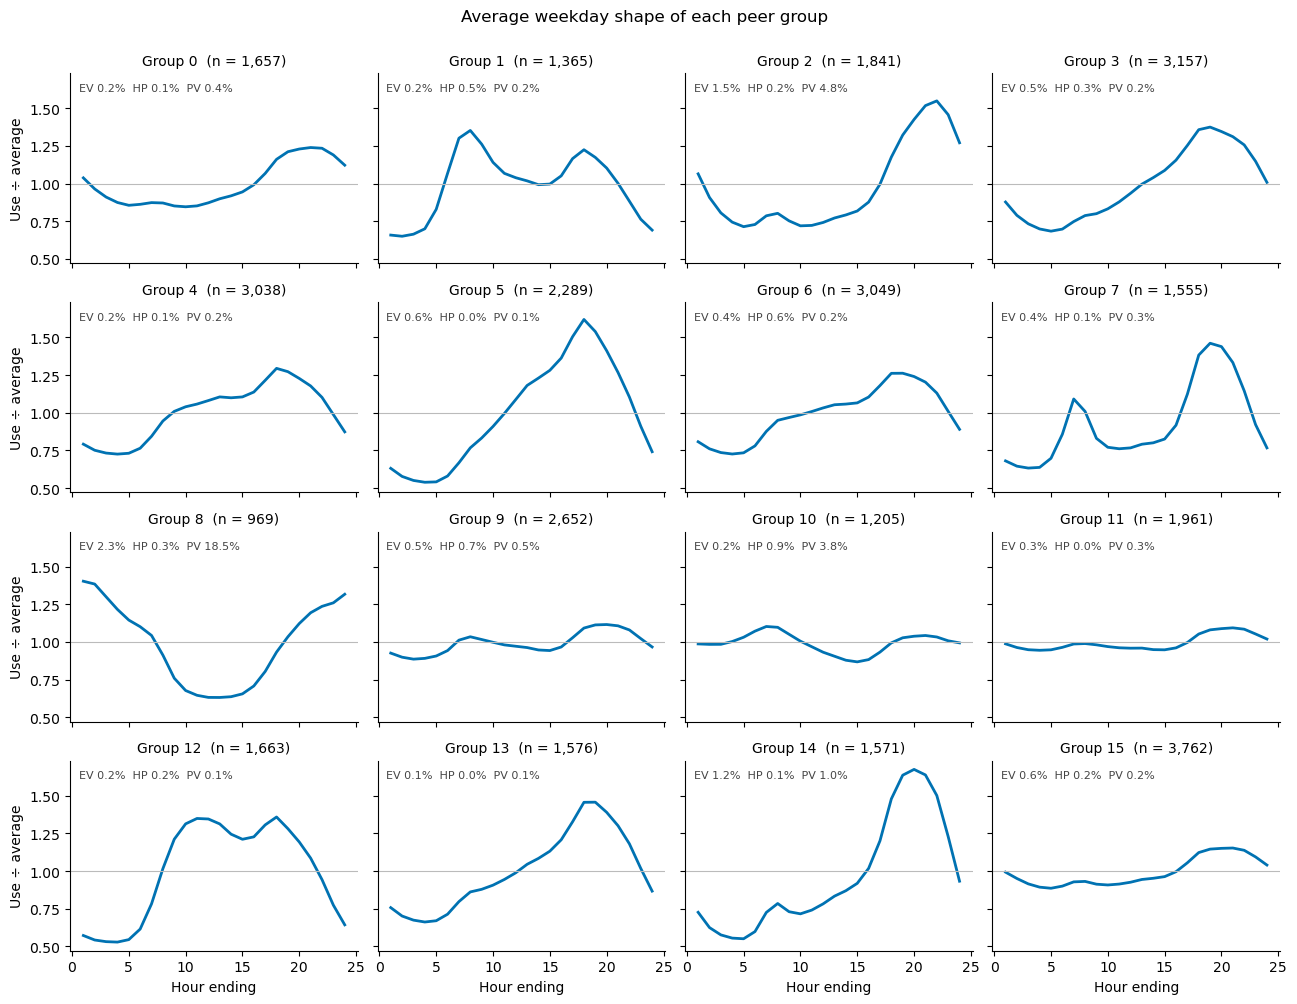

In [7]:
sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')
labels = peer_groups
for tab, customers in sheets.items():
    labels = labels.with_columns(
        pl.col('CUSTOMER_NUMBER').is_in(customers['CUSTOMER_NUMBER'].cast(pl.Int32).implode()).alias(tab.split()[0])
    )
group_mix = labels.group_by('peer_group').agg(pl.len().alias('n'), pl.col('EV').mean(), pl.col('HP').mean(), pl.col('PV').mean())

weekday = (shape.filter(pl.col('day_type') == 'Weekday')
           .join(peer_groups, on='CUSTOMER_NUMBER')
           .group_by('peer_group', 'hour_ending').agg(pl.col('n').mean())
           .sort('peer_group', 'hour_ending'))

fig, axes = plt.subplots(4, 4, figsize=(13, 10), sharex=True, sharey=True)
for g, ax in zip(range(N_PEER_GROUPS), axes.flat):
    p = weekday.filter(pl.col('peer_group') == g)
    mix = group_mix.filter(pl.col('peer_group') == g).row(0, named=True)
    ax.plot(p['hour_ending'], p['n'], color='#0072B2', linewidth=2)
    ax.axhline(1, color='#bbbbbb', linewidth=0.8)
    ax.set_title(f"Group {g}  (n = {mix['n']:,})", fontsize=10)
    ax.text(0.03, 0.95, f"EV {mix['EV']:.1%}  HP {mix['HP']:.1%}  PV {mix['PV']:.1%}",
            transform=ax.transAxes, fontsize=8, va='top', color='#444444')
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('Hour ending')
for ax in axes[:, 0]:
    ax.set_ylabel('Use ÷ average')
fig.suptitle('Average weekday shape of each peer group', y=1.0)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/peer_group_profiles.png', dpi=150)
plt.show()

## Usage relative to peers: the peer index

For every hour, each customer's use can be turned into a **peer-relative residual**:

1. **Normalize**: divide the customer's use by their own average hourly use (real readings only). A value of 1.0
   means a typical hour for that customer, so large and small homes can be compared.
2. **Peer index**: for each peer group, date and hour, average the normalized use of all customers in the group.
   This is what a typical member of the group did at that moment, given that day's weather, season and day of the
   week.
3. **Residual** = normalized use − peer index. Zero means the customer behaved like their peers. Positive means more
   than usual relative to peers; negative means less.

**Imputed hours** (from notebook 20) are left out of the peer index. They were filled with averages from the same
week, so including them would make customers look more consistent than they really are.

The peer index is saved to DuckDB as **`peer_index`** (group × date × hour, about 140,000 rows). Residuals are
recreated from it whenever they're needed, rather than stored for every customer and hour.

In [8]:
con.execute('''
    CREATE OR REPLACE TEMP TABLE normalized AS
    SELECT a.CUSTOMER_NUMBER, g.peer_group, a.usage_date, a.hour_ending, a.is_imputed,
           a.hourly_kwh / g.mean_kwh_real AS n
    FROM ami_analysis a JOIN customer_peer_groups g USING (CUSTOMER_NUMBER)
''')
con.execute('''
    CREATE OR REPLACE TABLE peer_index AS
    SELECT peer_group, usage_date, hour_ending, AVG(n) AS peer_n, COUNT(*) AS customers
    FROM normalized WHERE NOT is_imputed
    GROUP BY ALL ORDER BY ALL
''')
con.sql('''
    SELECT COUNT(*) AS rows, COUNT(DISTINCT peer_group) AS peer_groups, MIN(customers) AS fewest_customers_in_a_slot
    FROM peer_index
''').pl()

rows,peer_groups,fewest_customers_in_a_slot
i64,i64,i64
140128,16,622


## Cached arrays and customer status

The models and the later notebooks work on **customers × days × 24** NumPy arrays (hourly kWh, peer-relative
residuals, temperature), not on SQL tables. `avangrid.grids.load_hourly` builds them from `ami_analysis`,
`customer_peer_groups`, `peer_index` and `weather_features`, and caches them in `onedrive-export/Data/cache/`
(about 3.5 GB). The cache is rebuilt automatically whenever any of those tables changes. The daily peer-relative
signals that several feature families are built from are cached the same way.

**`customer_status`** has one row for each of the 35,725 customer numbers in the data dictionary, saying whether
and where each was excluded: no meter data, dropped as incomplete (notebook 20), excluded for very low usage (left
out of the peer groups above) or included. The connection used above is closed first, because these steps open
their own (DuckDB allows only one writer).

In [9]:
con.close()

from avangrid import grids, status  # noqa: E402
from avangrid.features import load_daily_signals  # noqa: E402

hd = grids.load_hourly()
load_daily_signals(hd)
status.build_customer_status()

[cache] building hourly (source data or code changed) ...


[cache] built hourly in 6s


[cache] building daily_signals (source data or code changed) ...


[cache] built daily_signals in 13s


status,customers,ev_list,hp_list,pv_list
str,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]"
"""included""",33310,179,86,389
"""excluded: low usage""",256,0,0,0
"""dropped: incomplete""",672,7,2,8
"""no meter data""",1487,14,12,37


## Feature families used by the models

Notebook 50 compares these families in rounds; each round keeps a family only if it improves the hidden-label AUC.
Every feature is defined in one sentence in `docs/feature-inventory.md`.

| Family | What it captures | Built by | First tested in notebook 50 |
|---|---|---|---|
| **A**: full-year features | This notebook's `customer_features`: size, time-of-day shares, summer midday dip, EV-like high-power hours, heating and cooling slopes | the SQL above (`avangrid.customer_features` is a NumPy copy) | Round 1 |
| **B**: peer-relative features | The same ideas measured against the peer index above, over any period | `avangrid.features.PeriodFeatures` | Round 1 |
| **Z, C**: mid-year change features | Step-change scores for each technology, and features measured only after a detected change | notebook 45 · `avangrid.stability` | Round 1 |
| **Signatures** | Solar index (midday dip tracking sunny days), charging blocks (EV), cold-response shape (HP) | `avangrid.signatures` | Round 2 |
| **Peak load** | How peaky the customer's use is, and how much they use in the grid's highest hours | `avangrid.signatures` | Round 3 |
| **R**: appliance-rule evidence | Evidence for AC, electric heating, water heater, pool, hot tub, EV charging and solar + battery | `avangrid.appliances` | Round 4 |
| **H**: heat-pump physics | Heating response by temperature band, defrost and deep-cold behaviour | `avangrid.physics` | Round 5 |
| **EV night features** | Night-by-night charging evidence for the multiple-instance EV model | `avangrid.ev_nights` | Round 5 |

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **Peer-relative analysis for very low users** (average under 0.05 kWh/hour) | Dividing by an average near zero blows up tiny fluctuations, so these customers are left out of the peer groups and everything built on them (models, appliance rules, battery simulation). They stay in `ami_analysis` and form their own "Minimal use / vacant" segment in notebook 70. |

Features that were computed but didn't improve a model are listed at the end of notebook 50, with the comparison that ruled each one out.